# AI, Data Science and Software Development Employment Analysis

**Student name:** [Marco Rubio Lira]
**Student ID:** 2022245

**GitHub repository:** [Add link later]
**Video presentation:** [Add link later]

## Introduction

This notebook explores employment and wages in occupations related to AI, Data Science and Software Development in the USA. It uses employment data from May 2023 published by the US Bureau of Labor Statistics.

In [1]:
import pandas as pd

df = pd.read_excel("/content/all_data_M_2023.xlsx")

df.head()

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


In [2]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Rows and columns: (413327, 32)

Column names:
['AREA', 'AREA_TITLE', 'AREA_TYPE', 'PRIM_STATE', 'NAICS', 'NAICS_TITLE', 'I_GROUP', 'OWN_CODE', 'OCC_CODE', 'OCC_TITLE', 'O_GROUP', 'TOT_EMP', 'EMP_PRSE', 'JOBS_1000', 'LOC_QUOTIENT', 'PCT_TOTAL', 'PCT_RPT', 'H_MEAN', 'A_MEAN', 'MEAN_PRSE', 'H_PCT10', 'H_PCT25', 'H_MEDIAN', 'H_PCT75', 'H_PCT90', 'A_PCT10', 'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90', 'ANNUAL', 'HOURLY']


In [3]:
occupations = [
    "Data Scientists",
    "Software Developers",
    "Computer and Information Research Scientists"
]

national = df[
    (df["AREA_TITLE"] == "U.S.") &
    (df["NAICS"].astype(str) == "000000") &
    (df["OWN_CODE"].astype(str) == "1235") &
    (df["OCC_TITLE"].isin(occupations))
].copy()

national[["OCC_CODE", "OCC_TITLE", "TOT_EMP", "A_MEAN"]]

,OCC_CODE,OCC_TITLE,TOT_EMP,A_MEAN
137,15-1220,Computer and Information Research Scientists,35210,157160
138,15-1221,Computer and Information Research Scientists,35210,157160
149,15-1252,Software Developers,1656880,138110
164,15-2050,Data Scientists,192710,119040
165,15-2051,Data Scientists,192710,119040


In [4]:
national = national[national["O_GROUP"] == "detailed"].copy()

national[["OCC_CODE", "OCC_TITLE", "TOT_EMP", "A_MEAN"]]

,OCC_CODE,OCC_TITLE,TOT_EMP,A_MEAN
138,15-1221,Computer and Information Research Scientists,35210,157160
149,15-1252,Software Developers,1656880,138110
165,15-2051,Data Scientists,192710,119040


In [5]:
national["TOT_EMP"] = pd.to_numeric(national["TOT_EMP"], errors="coerce")
national["A_MEAN"] = pd.to_numeric(national["A_MEAN"], errors="coerce")

print(national[["TOT_EMP", "A_MEAN"]].dtypes)
print("\nMissing values:")
print(national[["TOT_EMP", "A_MEAN"]].isna().sum())

TOT_EMP    int64
A_MEAN     int64
dtype: object

Missing values:
TOT_EMP    0
A_MEAN     0
dtype: int64


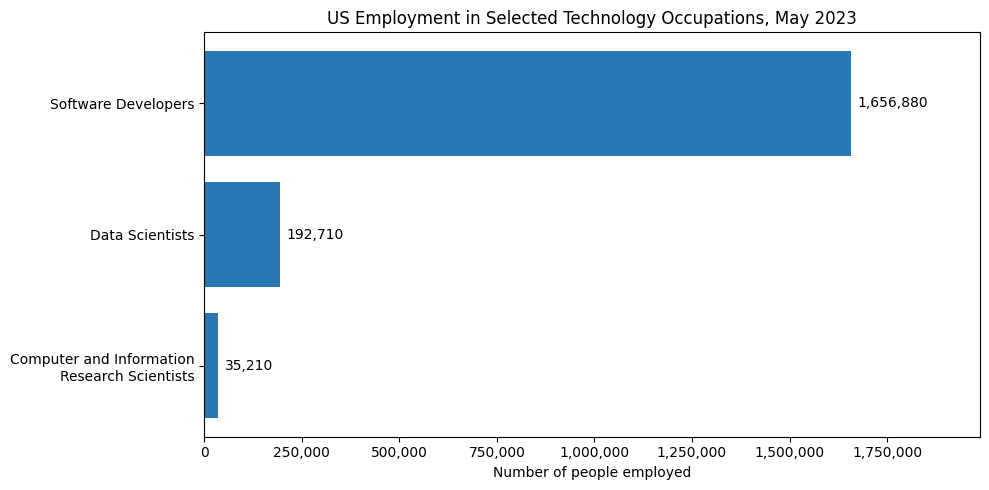

In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

chart_data = national.sort_values("TOT_EMP")

labels = chart_data["OCC_TITLE"].replace({
    "Computer and Information Research Scientists": "Computer and Information\nResearch Scientists"
})

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(labels, chart_data["TOT_EMP"], color="#2878B5")

ax.bar_label(bars, fmt="{:,.0f}", padding=5)
ax.set_title("US Employment in Selected Technology Occupations, May 2023")
ax.set_xlabel("Number of people employed")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_xlim(0, chart_data["TOT_EMP"].max() * 1.2)

plt.tight_layout()
plt.show()

### Visualisation 1: Employment by occupation

**Objective:** Compare employment in three US occupations related to AI, Data Science and Software Development in May 2023.

**Why this chart:** A horizontal bar chart makes it easy to compare employment numbers across occupations. It also leaves enough space for the long occupation names.

**Findings:** Software Developers had the highest employment, with 1,656,880 people. Data Scientists had 192,710, while Computer and Information Research Scientists had 35,210. Software Developers employed about 8.6 times as many people as Data Scientists.

These figures cover the full occupations, so they do not show how many people worked specifically in AI. They also represent one point in time and cannot show employment growth.